# 2장 2강 · 이미지 분류

## 실습 목표
- 사진 묶음이 CNN의 이미지별·클래스별 점수표가 되는 과정을 따라가고, 세 품종 소형 CNN을 실제로 학습합니다.
- 사전학습 ResNet18의 1,000개 Logit을 이미지별 확률로 바꾸고, 같은 사진의 1·2위 점수와 확률을 검산합니다.
- Oxford의 정답과 ImageNet의 예측을 이름으로 연결해 오답을 찾고, 확률 기준으로 검토 대상을 골랐을 때 생기는 누락을 설명합니다.

## 실습 환경 / 데이터
Python 3.10 이상, Jupyter, NumPy, pandas, Pillow, PyTorch, torchvision을 사용합니다. 필요한 경우 새 셀에서 %pip install numpy pandas pillow torch torchvision을 실행한 뒤 커널을 다시 시작하세요. CPU 실행이 가능합니다. ImageNet ResNet18 가중치는 첫 사용 시 약 45MB를 내려받거나 기존 캐시에서 불러옵니다.

Oxford ZIP 또는 압축을 푼 폴더를 노트북 옆에 두세요. 경로가 다르면 DATA_SOURCE를 수정하세요. 제공본에 공식 Train 원본이 없어 기존 val에 실제 파일이 있는 beagle·pug·Persian 각 20장씩을 학습용으로 사용합니다. 평가용으로는 공식 test의 같은 세 품종에서 각 20장씩 시드 42로 뽑습니다. 학습 60장과 평가 60장은 분리합니다. 평가 전에 학습을 12에포크, 예측 검토 기준을 최고 확률 80% 미만으로 고정합니다. 80%는 이 수업의 예시 기준입니다.

| 품종 | Oxford 원본 라벨 | 소형 CNN 출력 열 | ImageNet 대응 이름 |
|---|---:|---:|---|
| beagle | 4 | 0 | beagle |
| pug | 25 | 1 | pug |
| Persian | 23 | 2 | Persian cat |

## 실습 준비
아래 준비 셀은 그대로 실행하세요. 기본 CNN에는 세 개의 출력이 있고, 사전학습 모델은 1,000개 출력을 전부 사용합니다. 독립 과제는 준비 셀 후 바로 시작할 수 있습니다. 정답에는 측정값을 저장했습니다. 라이브러리 버전에 따라 마지막 소수 자리나 학습값이 조금 달라질 수 있습니다.

**재실행 안내**　필수 1의 결과를 처음부터 재현하려면 모델을 만드는 1-2 셀부터 다시 실행하세요. 이미 학습한 모델에 1-3만 반복하면 그 시점의 가중치에서 추가로 12에포크를 학습합니다.

In [1]:
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from io import BytesIO
from PIL import Image
from IPython.display import Markdown, display
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

# 제공 설정: CPU 실습에서 과도한 스레드 사용을 줄입니다.
torch.set_num_threads(2)
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)

PyTorch: 2.15.0+cpu
torchvision: 0.29.2+cpu


In [2]:
sources = [Path("oxford_dataset(1).zip"), Path("oxford_dataset.zip"), Path("oxford_dataset")]
DATA_SOURCE = next((path for path in sources if path.exists()), sources[0])

# 제공 코드: metadata.csv와 실제 이미지 파일이 있는지 확인합니다.
if not DATA_SOURCE.exists():
    raise FileNotFoundError("DATA_SOURCE를 실제 ZIP 또는 압축 해제 폴더 경로로 수정하세요.")
if DATA_SOURCE.is_file():
    with ZipFile(DATA_SOURCE) as zf:
        member_names = set(zf.namelist())
        meta_paths = sorted(n for n in member_names
                            if PurePosixPath(n).name == "metadata.csv" and "__MACOSX" not in n)
        if len(meta_paths) != 1:
            raise ValueError("metadata.csv가 하나 포함된 ZIP을 지정하세요.")
        parent = str(PurePosixPath(meta_paths[0]).parent)
        prefix = "" if parent == "." else parent + "/"
        metadata = pd.read_csv(BytesIO(zf.read(meta_paths[0])))
    def has_image(path):
        return prefix + str(path).replace("\\", "/") in member_names
    def load_rgb(path):
        with ZipFile(DATA_SOURCE) as zf:
            raw = zf.read(prefix + str(path).replace("\\", "/"))
        with Image.open(BytesIO(raw)) as im:
            return im.convert("RGB")
else:
    meta_paths = sorted(DATA_SOURCE.rglob("metadata.csv"))
    if len(meta_paths) != 1:
        raise ValueError("metadata.csv가 하나 포함된 데이터 폴더를 지정하세요.")
    data_root = meta_paths[0].parent
    metadata = pd.read_csv(meta_paths[0])
    def has_image(path):
        return (data_root / str(path)).is_file()
    def load_rgb(path):
        with Image.open(data_root / str(path)) as im:
            return im.convert("RGB")

available = metadata[metadata["image_path"].map(has_image)].copy()
pool_df = available[available["split"] == "val"].sort_values("image_path").reset_index(drop=True)
classes = ["beagle", "pug", "Persian"]
expected_imagenet = {"beagle": "beagle", "pug": "pug", "Persian": "Persian cat"}

train_rows = pool_df[pool_df.class_name.isin(classes)].copy().reset_index(drop=True)
test_pool = available[(available.split == "test") & available.class_name.isin(classes)]
test_parts = []
for name in classes:
    group = test_pool[test_pool.class_name == name].sort_values("image_path")
    test_parts.append(group.sample(n=20, random_state=42))
test_rows = pd.concat(test_parts, ignore_index=True)
to_local = {name:i for i, name in enumerate(classes)}
y_train = torch.tensor(train_rows.class_name.map(to_local).tolist(), dtype=torch.long)
y_test = torch.tensor(test_rows.class_name.map(to_local).tolist(), dtype=torch.long)
for split_rows in (train_rows, test_rows):
    assert split_rows.groupby("class_name").size().reindex(classes, fill_value=0).eq(20).all()
assert train_rows.image_id.is_unique and test_rows.image_id.is_unique
assert set(train_rows.image_id).isdisjoint(test_rows.image_id)
train_images = [load_rgb(path) for path in train_rows.image_path]
test_images = [load_rgb(path) for path in test_rows.image_path]
example_rows = train_rows.groupby("class_name", sort=False).first().loc[classes].reset_index()
example_images = [load_rgb(path) for path in example_rows.image_path]
single_image, single_row = example_images[0], example_rows.iloc[0]
def make_batch(images, preprocess):
    return torch.stack([preprocess(im) for im in images])

print("실제 JPEG 연결 행", len(available), "학습", len(train_rows), "평가", len(test_rows))
display(pd.crosstab(train_rows.class_name, train_rows.label))
display(example_rows[["image_id","class_name","label"]])

실제 JPEG 연결 행 4405 학습 60 평가 60


label,4,23,25
class_name,,,
Persian,0,20,0
beagle,20,0,0
pug,0,0,20


,image_id,class_name,label
0,beagle_110,beagle,4
1,pug_100,pug,25
2,Persian_100,Persian,23


In [3]:
# 공통 제공 코드 · 학습과 평가 반복문
def classify(model, X):
    model.eval()
    with torch.inference_mode():
        return torch.cat([model(batch).argmax(dim=1) for batch in X.split(10)])

def train_small(model, X, y):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    criterion = nn.CrossEntropyLoss()
    rng = torch.Generator().manual_seed(42)
    history = []
    model.train()
    for epoch in range(12):
        total = 0.0
        for idx in torch.randperm(len(y), generator=rng).split(10):
            optimizer.zero_grad()
            scores = model(X[idx])
            loss = criterion(scores, y[idx])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(idx)
        history.append(total / len(y))
    return history

## 필수 1. 소형 CNN의 점수표 읽기와 실제 학습

1. **1-1** 세 품종의 예시 사진을 표시하고 기본 전처리(224×224 Resize, ToTensor)로 하나의 배치를 만드세요. 각 축과 dtype을 설명하세요.
2. **1-2** 시드 42에서 Conv2d(3→8, 3×3, padding=1), ReLU, AdaptiveAvgPool2d(1×1), Flatten, Linear(8→3)를 구성하세요. 세 사진의 초기 점수와 예측 번호를 출력하고 한 행을 손으로 판독하세요.
3. **1-3** 같은 기본 전처리로 학습·평가 입력을 만드세요. 제공 학습 함수로 소형 CNN을 12에포크 학습하고 첫·마지막 손실, 실제 가중치 변화와 같은 평가 60장의 학습 전후 정답 수를 기록하세요. 마지막에는 실제 품종을 행, 예측 품종을 열로 하는 3×3 표와 품종별 정답 수를 구하세요.
4. **1-4** 채널 수와 클래스 수, 학습 손실과 평가 정확도의 차이를 설명하세요. 이 모델의 공간 평균 연산이 잃을 수 있는 정보와 관측된 결과를 구분해 해석하세요.

beagle_110 / beagle / 원본 크기(W,H): (437, 500)


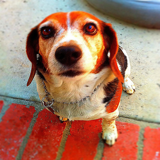

pug_100 / pug / 원본 크기(W,H): (333, 500)


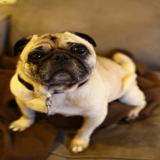

Persian_100 / Persian / 원본 크기(W,H): (500, 334)


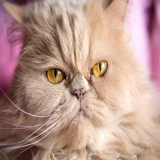

배치 shape (N, C, H, W): (3, 3, 224, 224) / dtype: torch.float32
값 범위: 0.0 ~ 1.0


In [4]:
# 1-1. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · example_rows와 example_images는 같은 순서입니다. 변환 전 사진과 변환 후 배치의 축을 연결해 보세요.
for row, im in zip(example_rows.itertuples(), example_images):
    print(row.image_id, "/", row.class_name, "/ 원본 크기(W,H):", im.size)
    display(im.resize((160, 160)))

basic_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
X_example = make_batch(example_images, basic_transform)
print("배치 shape (N, C, H, W):", tuple(X_example.shape), "/ dtype:", X_example.dtype)
print("값 범위:", round(X_example.min().item(), 4), "~", round(X_example.max().item(), 4))


In [5]:
# 1-2. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · 열 번호와 classes의 순서를 적은 뒤 첫 행에서 직접 최댓값을 찾아보세요.
torch.manual_seed(42)
small_cnn = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d((1, 1)),
    nn.Flatten(),
    nn.Linear(8, 3),
)
print(small_cnn)
small_cnn.eval()
with torch.inference_mode():
    init_scores = small_cnn(X_example)
init_pred = init_scores.argmax(dim=1)

score_table = pd.DataFrame(init_scores.numpy(),
                           columns=[f"{i}:{c}" for i, c in enumerate(classes)],
                           index=example_rows.class_name)
score_table["예측 번호"] = init_pred.numpy()
score_table["예측 이름"] = [classes[i] for i in init_pred]
print("점수 shape:", tuple(init_scores.shape))
display(score_table)

first = init_scores[0].tolist()
print("첫 행(실제", example_rows.class_name[0], ") 점수:", [round(v, 5) for v in first])
best = max(range(3), key=lambda i: first[i])
print("손으로 찾은 최댓값 열:", best, "→", classes[best], "/ argmax:", init_pred[0].item())


Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): AdaptiveAvgPool2d(output_size=(1, 1))
  (3): Flatten(start_dim=1, end_dim=-1)
  (4): Linear(in_features=8, out_features=3, bias=True)
)
점수 shape: (3, 3)


,0:beagle,1:pug,2:Persian,예측 번호,예측 이름
class_name,,,,,
beagle,-0.259262,0.326386,-0.076939,1,pug
pug,-0.224635,0.314387,-0.085725,1,pug
Persian,-0.272723,0.339881,-0.069841,1,pug


첫 행(실제 beagle ) 점수: [-0.25926, 0.32639, -0.07694]
손으로 찾은 최댓값 열: 1 → pug / argmax: 1


In [6]:
# 1-3. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · 제공 함수 classify(model, X)는 예측 열 번호를 반환합니다. train_small(model, X, y)는 같은 모델을 갱신하고 에포크별 손실을 반환합니다.
X_train = make_batch(train_images, basic_transform)
X_test = make_batch(test_images, basic_transform)
print("X_train:", tuple(X_train.shape), "/ X_test:", tuple(X_test.shape))

before_pred = classify(small_cnn, X_test)
before_correct = (before_pred == y_test).sum().item()
conv_before = small_cnn[0].weight.detach().clone()
fc_before = small_cnn[4].weight.detach().clone()

history = train_small(small_cnn, X_train, y_train)

after_pred = classify(small_cnn, X_test)
after_correct = (after_pred == y_test).sum().item()
train_correct = (classify(small_cnn, X_train) == y_train).sum().item()
print("에포크별 손실:", [round(v, 4) for v in history])
print("첫 손실:", round(history[0], 4), "/ 마지막 손실:", round(history[-1], 4))
print("Conv 가중치 최대 변화:", (small_cnn[0].weight - conv_before).abs().max().item())
print("Linear 가중치 최대 변화:", (small_cnn[4].weight - fc_before).abs().max().item())
print("평가 정답 수 (학습 전):", before_correct, "/", len(y_test))
print("평가 정답 수 (학습 후):", after_correct, "/", len(y_test))
print("학습 데이터 정답 수 (학습 후):", train_correct, "/", len(y_train))

confusion = pd.crosstab(pd.Series([classes[i] for i in y_test], name="실제"),
                        pd.Series([classes[i] for i in after_pred], name="예측")
                        ).reindex(index=classes, columns=classes, fill_value=0)
display(confusion)
per_class = pd.Series({c: confusion.loc[c, c] for c in classes}, name="품종별 정답 수(/20)")
display(per_class.to_frame())


X_train: (60, 3, 224, 224) / X_test: (60, 3, 224, 224)
에포크별 손실: [1.1393, 1.12, 1.1177, 1.1073, 1.1058, 1.1047, 1.104, 1.1025, 1.1017, 1.1008, 1.1, 1.1005]
첫 손실: 1.1393 / 마지막 손실: 1.1005
Conv 가중치 최대 변화: 0.04081243276596069
Linear 가중치 최대 변화: 0.06994369626045227
평가 정답 수 (학습 전): 20 / 60
평가 정답 수 (학습 후): 20 / 60
학습 데이터 정답 수 (학습 후): 20 / 60


예측,beagle,pug,Persian
실제,,,
beagle,0,20,0
pug,0,20,0
Persian,0,20,0


,품종별 정답 수(/20)
beagle,0
pug,20
Persian,0


### 문항별 해석 작성

**1-1 답변:** 예시 사진은 beagle_110(437×500), pug_100(333×500), Persian_100(500×334)입니다. 기본 전처리(Resize((224,224)) → ToTensor)를 적용해 쌓은 배치는 **(3, 3, 224, 224), torch.float32**이며 값 범위는 0.0~1.0입니다. 각 축의 의미는 다음과 같습니다.
- **첫 축 N=3:** 사진 수이며 example_rows 순서(beagle, pug, Persian)와 같습니다.
- **둘째 축 C=3:** RGB 채널입니다.
- **셋째·넷째 축 H, W=224:** 높이와 너비입니다.

원본 사진의 가로세로 비율이 서로 달라도 Resize로 모두 224×224가 되어 하나의 텐서로 쌓을 수 있습니다. 대신 비율이 왜곡됩니다.

**1-2 답변:** 시드 42로 만든 소형 CNN의 초기 점수표(shape (3, 3))입니다. 열 순서는 0: beagle, 1: pug, 2: Persian입니다.

| 실제 | 0:beagle | 1:pug | 2:Persian | 예측 |
|---|---:|---:|---:|---|
| beagle | -0.2593 | **0.3264** | -0.0769 | 1 (pug) |
| pug | -0.2246 | **0.3144** | -0.0857 | 1 (pug) |
| Persian | -0.2727 | **0.3399** | -0.0698 | 1 (pug) |

첫 행을 손으로 판독하면 -0.2593 < -0.0769 < 0.3264이므로 최댓값은 열 1(pug)이고 argmax 결과와 같습니다. 세 사진 모두 점수가 거의 같고 항상 pug를 고르는데, 학습 전 무작위 가중치에서는 사진 내용보다 Linear의 bias와 평균 밝기 차이가 점수를 좌우하기 때문입니다.

**1-3 답변:** 같은 기본 전처리로 X_train (60, 3, 224, 224)과 X_test (60, 3, 224, 224)를 만들었습니다. 12에포크 학습 결과는 다음과 같습니다.
- **손실:** 첫 에포크 1.1393, 마지막 에포크 1.1005로, 3클래스 무작위 추측 손실인 ln 3 ≈ 1.0986 근처에 머물렀습니다.
- **가중치 변화:** Conv 최대 0.0408, Linear 최대 0.0699로 실제로 갱신되었습니다.
- **평가 정답 수:** 학습 전 20/60, 학습 후 **20/60**으로 같습니다. 학습 데이터에서도 20/60입니다.

학습 후 3×3 표(행 = 실제, 열 = 예측)는 아래와 같습니다. 모든 사진을 pug로 예측해 품종별 정답 수는 beagle 0, pug 20, Persian 0입니다.

| 실제 \ 예측 | beagle | pug | Persian |
|---|---:|---:|---:|
| beagle | 0 | 20 | 0 |
| pug | 0 | 20 | 0 |
| Persian | 0 | 20 | 0 |

**1-4 답변:**
- **채널 수와 클래스 수:** 채널 수 8은 Conv가 만드는 특징 맵 개수로, 모델 내부의 표현 크기입니다. 클래스 수 3은 마지막 Linear(8→3)의 출력 열 개수로, 우리가 구분하려는 품종 수입니다. 둘은 서로 다른 개념이고, Linear가 8개 특징을 3개 클래스 점수로 바꿉니다.
- **학습 손실과 평가 정확도:** 손실은 1.139에서 1.100으로 조금 줄었지만, 확률이 균등 분포 쪽으로 정리된 정도일 뿐 argmax는 바뀌지 않아 정확도는 20/60(33.3%) 그대로입니다. 손실이 줄었다고 정답 수가 늘어나는 것은 아니며, 두 지표를 따로 확인해야 합니다.
- **공간 평균이 잃는 정보 (추론):** AdaptiveAvgPool(1×1)은 224×224 위치 정보를 모두 평균해 채널마다 숫자 하나만 남깁니다. 그래서 모양, 배치, 귀나 얼굴 같은 부위 정보가 사라지고, 사실상 8개 필터의 평균 반응(전체 색과 밝기 통계)만 남습니다. 3×3 Conv 한 층이라 수용 영역도 3픽셀에 불과합니다.
- **관측된 결과:** 학습 후에도 모든 사진을 pug로 예측했고 손실은 ln 3 근처에 머물렀습니다. 위 정보 손실과 작은 모델 용량, 적은 데이터(60장) 때문에 이 모델은 세 품종을 구분할 특징을 얻지 못했다고 해석됩니다. 다만 원인을 정확히 분리하려면 학습률, 에포크, 모델 깊이를 바꾼 추가 실험이 필요합니다.

---
## 필수 2. 사전학습 ResNet18 추론과 예측 확률 해석

**배경**  
준비된 `single_image`는 실제 beagle 이미지입니다. ImageNet 사전학습 ResNet18을 그대로 이용하여 이 이미지에 대한 **1,000개 클래스 점수**를 계산하려고 합니다.

**요구사항**
1. **2-1:** `ResNet18_Weights.DEFAULT`로 모델을 만들고 `eval()`을 적용하세요. `weights.transforms()`로 전처리한 이미지에 배치 차원을 추가하고, `torch.inference_mode()` 안에서 추론하세요. 입력·출력 shape를 출력하세요. 최종 분류기는 변경하지 않습니다.
2. **2-2:** Logit에서 `argmax(dim=1)`으로 예측 인덱스를 구하고 `weights.meta["categories"]`로 이름을 연결하세요. 예측 인덱스·이름·해당 Logit과 이 예제의 정답 대응 이름을 출력하세요.
3. **2-3:** `torch.softmax(logits,dim=1)`을 계산하세요. 확률의 shape·최솟값·최댓값·이미지별 합을 출력하고, 예측 클래스의 확률을 백분율로 표시하세요. 1·2위 클래스의 이름·점수·확률을 나란히 출력하세요. 두 확률의 비가 두 Logit 차이에 지수함수를 적용한 값과 일치하는지 검산하고, 순위 보존의 의미를 설명하세요.
4. **2-4:** ① eval과 inference_mode의 역할 차이 ② 이 출력이 Oxford 37품종 점수가 아닌 이유 ③ 높은 예측 확률을 실제 정답일 확률과 동일시할 수 없는 이유 ④ Oxford 37품종 전용 모델이 필요할 때의 다음 단계를 설명하세요.

**제출 결과**: 실제 사전학습 추론 코드, Logit·확률 출력, 올바른 클래스 매핑, 문항별 해석.

이미지: beagle_110 / 품종: beagle / 원본 크기: (437, 500)


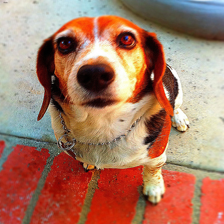

입력 shape: (1, 3, 224, 224) / dtype: torch.float32
출력(Logit) shape: (1, 1000)
분류기: Linear(in_features=512, out_features=1000, bias=True)


In [ ]:
# 2-1. 요구사항에 맞게 코드를 작성하세요.
# **2-1:** `ResNet18_Weights.DEFAULT`로 모델을 만들고 `eval()`을 적용하세요.
# `weights.transforms()`로 전처리한 이미지에 배치 차원을 추가하고, `torch.inference_mode()` 안에서 추론하세요. 
# 입력·출력 shape를 출력하세요. 최종 분류기는 변경하지 않습니다.
# 도움말 · single_image에는 사진 한 장이 들어 있습니다. 모델이 기대하는 첫 번째 축을 확인하세요.
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
model.eval()
preprocess = weights.transforms()

print("이미지:", single_row.image_id, "/ 품종:", single_row.class_name, "/ 원본 크기:", single_image.size)
display(single_image.resize((224, 224)))
x_single = preprocess(single_image).unsqueeze(0)
with torch.inference_mode():
    logits = model(x_single)
print("입력 shape:", tuple(x_single.shape), "/ dtype:", x_single.dtype)
print("출력(Logit) shape:", tuple(logits.shape))
print("분류기:", model.fc)


In [ ]:
# 2-2. 요구사항에 맞게 코드를 작성하세요.
# **2-2:** Logit에서 `argmax(dim=1)`으로 예측 인덱스를 구하고 `weights.meta["categories"]`로 이름을 연결하세요. 
# 예측 인덱스·이름·해당 Logit과 이 예제의 정답 대응 이름을 출력하세요.
# 도움말 · 점수, 그 점수의 열 번호, 그 번호가 가리키는 이름을 구분하세요.
categories = weights.meta["categories"]
pred_idx = logits.argmax(dim=1).item()
pred_name = categories[pred_idx]
answer_name = expected_imagenet[single_row.class_name]
answer_idx = categories.index(answer_name)
print("예측 인덱스:", pred_idx)
print("예측 이름  :", pred_name)
print("해당 Logit :", round(logits[0, pred_idx].item(), 4))
print("정답 대응 이름:", answer_name, f"(인덱스 {answer_idx}, Logit {logits[0, answer_idx].item():.4f})")
print("예측 == 정답?:", pred_name == answer_name)


예측 인덱스: 162
예측 이름  : beagle
해당 Logit : 15.9737
정답 대응 이름: beagle (인덱스 162, Logit 15.9737)
예측 == 정답?: True


In [ ]:
# 2-3. 요구사항에 맞게 코드를 작성하세요.
# **2-3:** `torch.softmax(logits,dim=1)`을 계산하세요. 확률의 shape·최솟값·최댓값·이미지별 합을 출력하고, 예측 클래스의 확률을 백분율로 표시하세요. 
# 1·2위 클래스의 이름·점수·확률을 나란히 출력하세요. 
# 두 확률의 비가 두 Logit 차이에 지수함수를 적용한 값과 일치하는지 검산하고, 순위 보존의 의미를 설명하세요.
# 도움말 · 한 사진의 1,000개 열에서 1위와 2위를 구하세요. 백분율로 반올림하기 전의 값으로 검산하세요.
probs = torch.softmax(logits, dim=1)
print("확률 shape:", tuple(probs.shape))
print("최솟값:", probs.min().item(), "/ 최댓값:", probs.max().item())
print("이미지별 합:", probs.sum(dim=1).tolist())
print(f"예측 클래스({pred_name}) 확률: {100 * probs[0, pred_idx].item():.2f}%")

top_logits, top_idx = logits.topk(2, dim=1)
top_probs = probs[0, top_idx[0]]
display(pd.DataFrame({
    "순위": [1, 2],
    "인덱스": top_idx[0].tolist(),
    "이름": [categories[i] for i in top_idx[0]],
    "Logit": top_logits[0].tolist(),
    "확률(%)": (100 * top_probs).tolist(),
}))

ratio = (top_probs[0] / top_probs[1]).item()
exp_diff = torch.exp(top_logits[0, 0] - top_logits[0, 1]).item()
print("p1 / p2              :", ratio)
print("exp(logit1 - logit2) :", exp_diff)
print("일치 여부(isclose)   :", abs(ratio - exp_diff) <= 1e-4 * exp_diff)
print("Logit 순위 == 확률 순위:", torch.equal(logits.argsort(dim=1, descending=True),
                                              probs.argsort(dim=1, descending=True)))


확률 shape: (1, 1000)
최솟값: 1.0597307059656558e-10 / 최댓값: 0.5867877006530762
이미지별 합: [1.0000005960464478]
예측 클래스(beagle) 확률: 58.68%


,순위,인덱스,이름,Logit,확률(%)
0,1,162,beagle,15.973704,58.678772
1,2,161,basset,15.298659,29.875330


p1 / p2              : 1.9641213417053223
exp(logit1 - logit2) : 1.9641213417053223
일치 여부(isclose)   : True
Logit 순위 == 확률 순위: True


### 문항별 해석 작성

**2-1 답변:** `ResNet18_Weights.DEFAULT`로 모델을 만들고 `eval()`을 적용했습니다. `weights.transforms()`로 beagle_110을 전처리하고 `unsqueeze(0)`으로 배치 축을 추가해 입력은 **(1, 3, 224, 224), float32**입니다. `torch.inference_mode()` 안에서 추론한 출력은 **(1, 1000)**이며, 분류기는 바꾸지 않은 `Linear(512 → 1000)`입니다.

**2-2 답변:** `argmax(dim=1)` 결과 예측 인덱스는 **162**이고, `weights.meta["categories"][162]`는 **beagle**, 해당 Logit은 **15.9737**입니다. 이 예제의 정답 대응 이름도 beagle(인덱스 162)이므로 예측이 맞았습니다. 점수(15.97), 그 점수가 있는 열 번호(162), 그 번호가 가리키는 이름(beagle)은 서로 다른 값입니다. Oxford 라벨 4와 ImageNet 인덱스 162도 서로 다른 번호 체계입니다.

**2-3 답변:** Softmax 결과는 다음과 같습니다.
- **확률:** shape (1, 1000), 최솟값 1.06e-10, 최댓값 0.5868, 이미지별 합 1.0000006(float32 반올림 오차)
- **예측 클래스 확률:** beagle **58.68%**

| 순위 | 인덱스 | 이름 | Logit | 확률 |
|---|---:|---|---:|---:|
| 1 | 162 | beagle | 15.9737 | 58.68% |
| 2 | 161 | basset | 15.2987 | 29.88% |

반올림 전 값으로 검산하면 p1/p2 = **1.96412134**, exp(15.9737 − 15.2987) = **1.96412134**로 일치합니다. Softmax의 분모는 모든 클래스에서 공통이라 약분되므로, 두 확률의 비는 두 Logit 차이의 지수값만으로 정해집니다. exp는 단조 증가 함수라 **Logit 순위와 확률 순위가 1,000개 전부 같습니다**(True). 따라서 예측 클래스는 Logit에서 argmax를 하든 확률에서 argmax를 하든 같고, Softmax는 순위를 바꾸지 않고 점수를 합이 1인 상대적 비율로 바꿀 뿐입니다.

**2-4 답변:**
- ① **eval과 inference_mode:** `eval()`은 모델의 동작 모드를 바꿉니다. BatchNorm이 배치 통계 대신 저장된 평균·분산을 쓰고 Dropout을 끄므로, 추론 결과가 결정적이 됩니다. `inference_mode()`는 autograd 기록을 끄는 실행 문맥으로, 기울기 계산용 그래프를 만들지 않아 메모리와 속도를 아낍니다. 출력값 자체에는 영향을 주지 않습니다. 하나는 '어떻게 계산하나', 다른 하나는 '기울기를 추적하나'를 정하므로 둘 다 필요합니다.
- ② **Oxford 37품종 점수가 아닌 이유:** 최종 fc가 ImageNet 1,000개 클래스(물고기, 자동차 등 포함)로 학습되었기 때문입니다. 열 162는 ImageNet의 'beagle'이고, Oxford 라벨 번호와 무관합니다. Oxford 37품종 중에는 ImageNet에 같은 이름이 없는 품종도 있습니다.
- ③ **높은 확률 ≠ 정답일 확률:** Softmax 확률은 1,000개 클래스 사이의 상대 점수일 뿐 보정된 정답 확률이 아닙니다. 딥러닝 모델은 과신하는 경향이 있고, 분포가 다른 사진에서도 높은 확률을 낼 수 있습니다. 실제로 과제 1에서 확률 86.4%인 오답(pug_74 → bull mastiff)이 나왔습니다.
- ④ **Oxford 37품종 전용 모델의 다음 단계:** fc를 512→37로 교체하고, Oxford 학습 데이터로 fc(필요하면 layer4까지) 전이학습을 합니다. 그다음 분리된 검증·평가 세트로 정답 수를 확인하고, 필요하면 확률 보정(temperature scaling 등)을 적용합니다.

## 과제 1. 독립된 평가 사진 60장으로 예측 오류와 확률 기준 검토하기 · 필수 수준

1. **3-1** 준비 셀의 test_images, test_rows에서 출발하세요. 사전학습 ResNet18과 권장 전처리를 새로 구성해 10장씩 추론한 뒤, 원래 순서를 유지한 60×1,000 Logit 표를 만드세요.
2. **3-2** 사진별로 1,000개 클래스의 Softmax를 계산하세요. 파일명, 원본 품종, 대응 정답 이름, 예측 번호·이름, 선택 Logit, 최고 확률, 정답 일치 여부를 표에 담으세요. 확률 합과 품종별·전체 정답 수를 검산하세요.
3. **3-3** 최고 확률 80% 미만이면 사람이 검토한다고 가정하세요. 검토·통과 집단별 정답과 오답 수, 잡힌 오답과 놓친 오답을 구하세요. 가장 높은 확률의 오답과 가장 낮은 확률의 정답을 원본 사진과 함께 확인하세요. 해당 사례가 없으면 없다고 기록하세요.
4. **3-4** 위 파일 중 한 장을 근거로 확률과 정답 여부의 차이를 설명하세요. 이 기준이 수업 표본에서 갖는 이점과 한계, 전체 Oxford 품종에 일반화할 수 있는 범위를 적으세요.

**제출 결과**　일관된 순서의 추론 표, 품종별 집계, 검토 기준의 결과, 실제 정답·오답 사례와 해석. 확률 기준은 평가 결과를 보기 전에 정한 예시 값입니다.

In [10]:
# 3-1. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · test_rows의 행 순서를 보존하세요. 첫 묶음과 마지막 묶음이 담당하는 행 범위를 먼저 적어 보세요.
weights3 = ResNet18_Weights.DEFAULT
model3 = resnet18(weights=weights3).eval()
preprocess3 = weights3.transforms()
categories3 = weights3.meta["categories"]

X3 = make_batch(test_images, preprocess3)
chunks = []
with torch.inference_mode():
    for start in range(0, len(X3), 10):
        end = min(start + 10, len(X3))
        chunks.append(model3(X3[start:end]))
        print(f"묶음 {start // 10 + 1}: 행 {start}~{end - 1}")
logits3 = torch.cat(chunks)

logit_table = pd.DataFrame(logits3.numpy(), index=test_rows.image_id, columns=categories3)
print("Logit 표 shape:", logit_table.shape)
print("행 순서 = test_rows 순서:", list(logit_table.index) == test_rows.image_id.tolist())
display(logit_table.iloc[[0, 1, -1], :5])


묶음 1: 행 0~9
묶음 2: 행 10~19
묶음 3: 행 20~29
묶음 4: 행 30~39
묶음 5: 행 40~49
묶음 6: 행 50~59
Logit 표 shape: (60, 1000)
행 순서 = test_rows 순서: True


,tench,goldfish,great white shark,tiger shark,hammerhead
image_id,,,,,
beagle_84,-1.802185,-0.652593,-1.153209,-4.047314,-0.371355
beagle_57,0.351971,-1.390862,-0.218158,-1.109887,1.042714
Persian_29,-0.367875,-3.409929,-2.333822,-3.936174,-2.967455


In [11]:
# 3-2. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · 세 품종으로 출력을 제한하지 않습니다. 모델이 다른 이름을 고른 경우도 표에 남기세요.
probs3 = torch.softmax(logits3, dim=1)
top_p, top_i = probs3.max(dim=1)
result = pd.DataFrame({
    "파일명": [Path(p).name for p in test_rows.image_path],
    "원본 품종": test_rows.class_name.values,
    "정답 이름": test_rows.class_name.map(expected_imagenet).values,
    "예측 번호": top_i.numpy(),
    "예측 이름": [categories3[i] for i in top_i],
    "선택 Logit": logits3[torch.arange(len(top_i)), top_i].numpy().round(4),
    "최고 확률": top_p.numpy().round(4),
})
result["정답"] = result["예측 이름"] == result["정답 이름"]
pd.set_option("display.max_rows", 80)
display(result)

print("확률 합 범위:", probs3.sum(dim=1).min().item(), "~", probs3.sum(dim=1).max().item())
summary = result.groupby("원본 품종", sort=False)["정답"].agg(["sum", "count"]).loc[classes]
summary.columns = ["정답 수", "사진 수"]
display(summary)
print("전체 정답:", result["정답"].sum(), "/", len(result), "(품종별 합:", summary["정답 수"].sum(), ")")
wrong = result[~result["정답"]]
print("오답에서 고른 이름:", wrong["예측 이름"].value_counts().to_dict())


,파일명,원본 품종,정답 이름,예측 번호,예측 이름,선택 Logit,최고 확률,정답
0,beagle_84.jpg,beagle,beagle,162,beagle,16.959801,0.7364,True
1,beagle_57.jpg,beagle,beagle,162,beagle,14.615600,0.4006,True
2,beagle_72.jpg,beagle,beagle,162,beagle,15.202600,0.9665,True
3,beagle_5.jpg,beagle,beagle,162,beagle,13.030400,0.4467,True
4,beagle_49.jpg,beagle,beagle,162,beagle,15.706600,0.6980,True
5,beagle_44.jpg,beagle,beagle,162,beagle,15.849000,0.7149,True
6,beagle_29.jpg,beagle,beagle,164,bluetick,13.953400,0.2987,False
7,beagle_81.jpg,beagle,beagle,162,beagle,12.291300,0.5422,True
8,beagle_201.jpg,beagle,beagle,162,beagle,18.394199,0.9827,True
9,beagle_1.jpg,beagle,beagle,162,beagle,15.148100,0.6700,True


확률 합 범위: 0.9999993443489075 ~ 1.000001072883606


,정답 수,사진 수
원본 품종,,
beagle,18,20
pug,17,20
Persian,19,20


전체 정답: 54 / 60 (품종별 합: 54 )
오답에서 고른 이름: {'bull mastiff': 2, 'bluetick': 1, 'Walker hound': 1, 'French bulldog': 1, 'cairn': 1}


정답,오답,정답
검토,,
검토(<80%),5,13
통과(≥80%),1,41


네 칸의 합: 60 / 60
잡힌 오답(검토로 걸러짐): 5 / 놓친 오답(통과했지만 오답): 1
검토 대상 중 정답(불필요한 검토): 13
가장 높은 확률의 오답: pug_74.jpg / 실제 pug / 예측 bull mastiff / 확률 0.8641 / 검토 False


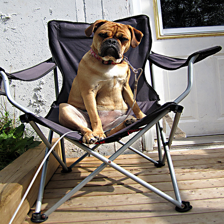

가장 낮은 확률의 정답: beagle_36.jpg / 실제 beagle / 예측 beagle / 확률 0.3492 / 검토 True


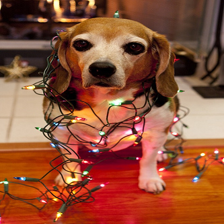

,파일명,원본 품종,정답 이름,예측 번호,예측 이름,선택 Logit,최고 확률,정답,검토
32,pug_74.jpg,pug,pug,243,bull mastiff,16.8309,0.8641,False,False


In [12]:
# 3-3. 요구사항에 맞게 코드를 작성하세요.

# 도움말 · 정답 여부와 검토 여부는 서로 다른 두 판단입니다. True/False 조합 네 칸의 합이 평가 사진 수인지 확인하세요.
THRESHOLD = 0.80
result["검토"] = result["최고 확률"] < THRESHOLD
table = pd.crosstab(result["검토"].map({True: "검토(<80%)", False: "통과(≥80%)"}),
                    result["정답"].map({True: "정답", False: "오답"}))
display(table)
print("네 칸의 합:", int(table.values.sum()), "/", len(result))
caught = result[result["검토"] & ~result["정답"]]
missed = result[~result["검토"] & ~result["정답"]]
print("잡힌 오답(검토로 걸러짐):", len(caught), "/ 놓친 오답(통과했지만 오답):", len(missed))
print("검토 대상 중 정답(불필요한 검토):", int((result["검토"] & result["정답"]).sum()))

def show_case(title, frame, pick):
    if frame.empty:
        print(title, ": 해당 사례 없음")
        return
    idx = pick(frame)
    r = result.loc[idx]
    print(f"{title}: {r['파일명']} / 실제 {r['원본 품종']} / 예측 {r['예측 이름']} / 확률 {r['최고 확률']:.4f} / 검토 {r['검토']}")
    display(test_images[idx].resize((224, 224)))

show_case("가장 높은 확률의 오답", result[~result["정답"]], lambda f: f["최고 확률"].idxmax())
show_case("가장 낮은 확률의 정답", result[result["정답"]], lambda f: f["최고 확률"].idxmin())
if not missed.empty:
    display(missed)


### 문항별 해석 작성

**3-1 답변:** 새로 만든 사전학습 ResNet18(`eval`)과 `weights.transforms()`로 test_images 60장을 (60, 3, 224, 224)로 만들고, 10장씩 6묶음으로 추론했습니다(묶음 1: 행 0~9, …, 묶음 6: 행 50~59). `torch.cat`으로 이어 붙인 Logit 표는 **(60, 1000)**이고, 행 인덱스가 `test_rows.image_id` 순서와 일치함을 확인했습니다(True). 첫 행은 beagle_84, 마지막 행은 Persian_29입니다.

**3-2 답변:**
- **확률 합 검산:** 사진별 Softmax 합은 0.9999993~1.0000011로 모두 1입니다(float32 오차 범위).
- **품종별 정답 수:** beagle **18/20**, pug **17/20**, Persian **19/20**
- **전체 정답 수:** **54/60 (90%)**이며 품종별 합 18+17+19 = 54와 일치합니다.

출력을 세 품종으로 제한하지 않았기 때문에 오답 6장은 모두 비슷하게 생긴 다른 ImageNet 클래스를 골랐습니다.
- beagle_29 → bluetick, beagle_25 → Walker hound: 같은 하운드 계열
- pug_49 → French bulldog, pug_24·pug_74 → bull mastiff: 주름진 얼굴의 단두종
- Persian_224 → cairn: 장모 테리어

**3-3 답변:** 최고 확률 80% 미만을 '검토', 이상을 '통과'로 나눈 결과입니다.

| | 정답 | 오답 | 합 |
|---|---:|---:|---:|
| 검토(<80%) | 13 | 5 | 18 |
| 통과(≥80%) | 41 | **1** | 42 |

- **네 칸 검산:** 합은 60/60입니다.
- **잡힌 오답:** 5개 (beagle_29 29.9%, beagle_25 55.5%, pug_49 69.1%, pug_24 66.2%, Persian_224 34.2%)
- **놓친 오답:** 1개 (pug_74.jpg)
- **불필요한 검토:** 검토 대상 18장 중 13장은 정답이었습니다.
- **가장 높은 확률의 오답:** **pug_74.jpg**, 실제 pug, 예측 bull mastiff, 확률 **86.41%**. 80%를 넘었으므로 검토 없이 통과했습니다.
- **가장 낮은 확률의 정답:** **beagle_36.jpg**, 실제 beagle, 예측 beagle, 확률 **34.92%**. 맞았지만 검토 대상이 되었습니다.

**3-4 답변:**
- **확률과 정답 여부의 차이:** pug_74.jpg는 모델이 86.4%로 bull mastiff라고 확신했지만 틀렸습니다. 반대로 beagle_36.jpg는 34.9%밖에 안 되지만 맞았습니다. 최고 확률은 '모델이 1,000개 클래스 중 이 클래스를 얼마나 상대적으로 선호하는가'이지 '이 예측이 맞을 확률'이 아닙니다. 그래서 확률이 높아도 오답일 수 있고, 낮아도 정답일 수 있습니다.
- **이점:** 이 표본에서 80% 기준은 사진 18장(30%)만 사람이 보고도 오답 6개 중 5개(83%)를 잡았습니다. 통과한 42장의 정확도는 41/42(97.6%)로, 전체 정확도 90%보다 높아집니다.
- **한계:** 높은 확률의 오답(pug_74)은 구조적으로 놓칩니다. 검토 대상의 72%(13/18)는 이미 정답이라 검토 비용이 듭니다. 또 평가 사진이 60장이고 오답이 6개뿐이라 '6개 중 5개 포착'은 오답 하나에 결과가 크게 흔들립니다. 80%는 미리 정한 예시 값이고 최적화하지 않았습니다.
- **일반화 범위:** 세 품종은 모두 ImageNet에 같은 이름의 클래스가 있어 사전학습 모델이 잘 맞히는 쉬운 경우입니다. Oxford 37품종 중 ImageNet에 대응 이름이 없거나 비슷한 품종이 많은 경우에는 정답 수와 확률 분포 모두 달라질 수 있습니다. 따라서 이 결과(정확도 90%, 오답 6개 중 5개 포착)를 Oxford 전체로 일반화할 수 없고, 이 세 품종과 이 표본 안에서의 관측으로만 해석해야 합니다.

## 실습 마무리

1. **어떤 문제가 있었는가?**
   - **초기 모델의 클래스 열:** 학습 전 소형 CNN은 세 사진을 모두 열 1(pug)로 예측했습니다. 열 번호를 품종으로 해석하는 것은 학습 후에만 의미가 있습니다.
   - **Oxford 라벨과 ImageNet 라벨:** Oxford의 beagle은 라벨 4, ImageNet의 beagle은 인덱스 162로 번호 체계가 다릅니다. 이름으로 대응해야 합니다(예: Persian → 'Persian cat').
   - **높은 확률의 의미:** 높은 확률을 정답 확률로 착각하면, pug_74처럼 86.4%로 확신한 오답을 검토 없이 통과시키게 됩니다.
2. **어떻게 개선했는가?**
   - **실제 학습:** 소형 CNN의 가중치를 실제로 갱신하고(Conv Δmax 0.041), 학습 전후 정답 수를 비교했습니다.
   - **권장 전처리:** 사전학습 때와 같은 입력 분포(크기·정규화)를 맞췄습니다.
   - **이미지별 Softmax(dim=1):** 사진마다 1,000개 클래스 확률의 합이 1이 되도록 했습니다.
   - **이름 대응과 정답 대조:** `expected_imagenet`으로 Oxford 품종을 ImageNet 이름에 연결하고, 예측 이름과 비교해 정답 여부를 판정했습니다.
3. **무엇을 근거로 판단했는가?**
   - **소형 CNN:** 학습 전후 평가 정답이 모두 20/60이고, 모든 사진을 pug로 예측했습니다. 손실은 1.139에서 1.100으로, ln 3 근처에 머물렀습니다. 이 구조와 데이터로는 품종 구분을 학습하지 못했습니다.
   - **사전학습 ResNet18:** 평가 60장 중 54장(90%)을 맞혔습니다(beagle 18, pug 17, Persian 19).
   - **80% 검토 기준:** 오답 6개 중 5개를 잡았지만, pug_74.jpg(bull mastiff 86.4%) 1개를 놓쳤습니다.
   - **결론:** 확률 기준은 검토량을 줄이는 보조 수단으로 쓸 수 있지만 정답을 보장하지는 않습니다. 이 결론은 ImageNet에 대응 이름이 있는 세 품종, 60장 표본에 한정됩니다.